1. Set up

In [2]:
import os
import numpy as np
import pandas as pd
import joblib
import time
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

import shap


# ── Đường dẫn — dùng chung logic với modeling.ipynb (BASE_DIR tính động theo cwd) ──
BASE_DIR       = os.path.abspath(os.path.join(os.getcwd(), '..'))
MODELS_DIR     = os.path.join(BASE_DIR, 'Models')
TRAIN_TEST_DIR = os.path.join(MODELS_DIR, 'Train_Test')
REPORTS_DIR    = os.path.join(BASE_DIR, 'Reports')
IMAGES_DIR     = os.path.join(REPORTS_DIR, 'Images', 'shap')
os.makedirs(IMAGES_DIR, exist_ok=True)

print(f"BASE_DIR   : {BASE_DIR}")
print(f"MODELS_DIR : {MODELS_DIR}")
print(f"IMAGES_DIR : {IMAGES_DIR}")

BASE_DIR   : d:\Study Assets\Final Project\PhishingGuard
MODELS_DIR : d:\Study Assets\Final Project\PhishingGuard\Models
IMAGES_DIR : d:\Study Assets\Final Project\PhishingGuard\Reports\Images\shap



2. Load Val Set + Hard Cases + Scaler

In [3]:
# ── Val set Dataset 1 (dùng để tính Global Feature Importance) ──
val1 = pd.read_csv(os.path.join(TRAIN_TEST_DIR, 'dataset1', 'val.csv'))
FEATURE_COLS = [c for c in val1.columns if c not in ['URL', 'Label']]

# Label mapping — LabelEncoder gốc sort alphabet, tái tạo lại chính xác mapping đó
LABEL_NAMES_1 = sorted(val1['Label'].unique())
label_to_idx = {name: i for i, name in enumerate(LABEL_NAMES_1)}
print(f"Label mapping: {label_to_idx}")

X_val1 = val1[FEATURE_COLS].values
y_val1 = val1['Label'].map(label_to_idx).values

# ── Scaler đã lưu — bắt buộc dùng lại đúng scaler đã fit lúc train, không fit mới ──
scaler1 = joblib.load(os.path.join(MODELS_DIR, 'dataset1', 'scaler1.pkl'))
X_val1_scaled = scaler1.transform(X_val1)

print(f"\nVal set Dataset 1: {X_val1.shape}")
print(f"Feature columns ({len(FEATURE_COLS)}): {FEATURE_COLS}")

# ── Hard cases từ Error Analysis (modeling.ipynb, mục 13.5) ──
hard_cases = pd.read_csv(os.path.join(MODELS_DIR, 'hard_cases_dataset1.csv'))
X_hard = hard_cases[FEATURE_COLS].values
y_hard = hard_cases['Label'].map(label_to_idx).values
X_hard_scaled = scaler1.transform(X_hard)

print(f"\nHard cases: {X_hard.shape[0]} sample")
print(hard_cases['Label'].value_counts())

Label mapping: {'benign': 0, 'defacement': 1, 'malware': 2, 'phishing': 3}

Val set Dataset 1: (101949, 32)
Feature columns (32): ['url_length', 'domain_length', 'path_length', 'num_dots', 'num_hyphens', 'num_underscores', 'num_slashes', 'num_at', 'num_question_marks', 'num_equals', 'num_ampersands', 'num_percent', 'num_digits', 'digit_ratio', 'letter_ratio', 'url_entropy', 'domain_entropy', 'num_subdomains', 'has_ip_address', 'has_https', 'is_suspicious_tld', 'has_port', 'path_depth', 'num_query_params', 'has_fragment', 'is_shortened_url', 'has_suspicious_word', 'consonant_ratio', 'vowel_ratio', 'longest_token_length', 'avg_token_length', 'special_char_ratio']

Hard cases: 7122 sample
Label
defacement    2596
phishing      2530
benign        1464
malware        532
Name: count, dtype: int64


2. Load 16 model Dataset 1 + Grouping by SHAP explainer type

In [4]:
# ── Phân nhóm model theo loại explainer phù hợp (đã chốt) ──
TREE_MODELS = [
    'decision_tree', 'random_forest', 'xgboost',
    'lightgbm', 'extra_trees'
]  # shap.TreeExplainer — đã bỏ gradient_boosting (shap issue #2887, #479 — không hỗ trợ multiclass)

LINEAR_MODELS = [
    'logistic_regression_custom_manual', 'svm', 'sgd'
]  # shap.LinearExplainer — đã bỏ logistic_regression (balanced), giữ bản custom_manual (macro-F1 0.71 > 0.65)

KERNEL_MODELS = [
    'bagging', 'knn'
]  # shap.KernelExplainer — chỉ giữ 2 model tốt nhất nhóm này (0.9160, 0.9038)
   # đã bỏ svc_rbf, svc_poly, nusvc, adaboost — accuracy thấp hơn (0.78-0.86),
   # không phải model sẽ chọn làm kết luận cuối, không đáng chi phí KernelExplainer

# Model cần input đã scale (StandardScaler)
SCALED_MODELS = {
    'knn', 'svm', 'sgd', 'logistic_regression_custom_manual'
}

ALL_MODEL_KEYS = TREE_MODELS + LINEAR_MODELS + KERNEL_MODELS
print(f"Tổng số model đưa vào Explainability: {len(ALL_MODEL_KEYS)}/16")

models_ds1 = {}
for key in ALL_MODEL_KEYS:
    path = os.path.join(MODELS_DIR, 'dataset1', f'{key}.pkl')
    if not os.path.exists(path):
        print(f"  [MISSING] {path}")
        continue
    models_ds1[key] = joblib.load(path)

print(f"Đã load {len(models_ds1)}/{len(ALL_MODEL_KEYS)} model Dataset 1")
print(f"\n  Tree-based   ({len(TREE_MODELS)}) : {TREE_MODELS}")
print(f"  Linear       ({len(LINEAR_MODELS)}) : {LINEAR_MODELS}")
print(f"  Kernel-based ({len(KERNEL_MODELS)}) : {KERNEL_MODELS}")

def get_input(model_key, X_raw, X_scaled):
    """Trả về đúng loại input (scaled/raw) theo model_key."""
    return X_scaled if model_key in SCALED_MODELS else X_raw

Tổng số model đưa vào Explainability: 10/16
Đã load 10/10 model Dataset 1

  Tree-based   (5) : ['decision_tree', 'random_forest', 'xgboost', 'lightgbm', 'extra_trees']
  Linear       (3) : ['logistic_regression_custom_manual', 'svm', 'sgd']
  Kernel-based (2) : ['bagging', 'knn']


3. Calculate SHAP for 10 models

In [5]:
# ── 3. Global Feature Importance (SHAP) — Tree + Linear models (10 model) ──

N_BACKGROUND     = 200   # nền cho LinearExplainer
N_GLOBAL_SAMPLE  = 3000  # số sample val dùng để tính global importance

rng = np.random.RandomState(42)
sample_idx = rng.choice(len(X_val1), size=N_GLOBAL_SAMPLE, replace=False)

shap_values_global = {}  # model_key -> {'values': list mảng SHAP theo từng class, 'X_sample': ...}

for model_key in TREE_MODELS + LINEAR_MODELS:
    model = models_ds1[model_key]
    X_full = get_input(model_key, X_val1, X_val1_scaled)
    X_sample = X_full[sample_idx]

    t0 = time.time()
    try:
        if model_key in TREE_MODELS:
            explainer = shap.TreeExplainer(model)
            sv = explainer.shap_values(X_sample)
        else:  # LINEAR_MODELS
            bg_idx = rng.choice(len(X_full), N_BACKGROUND, replace=False)
            background = X_full[bg_idx]
            explainer = shap.LinearExplainer(model, background)
            sv = explainer.shap_values(X_sample)

        # Chuẩn hóa về dạng list-of-arrays theo từng class (multiclass 4 lớp)
        if isinstance(sv, list):
            sv_list = sv
        elif sv.ndim == 3:
            sv_list = [sv[:, :, c] for c in range(sv.shape[2])]
        else:
            sv_list = [sv]

        elapsed = round(time.time() - t0, 1)
        shap_values_global[model_key] = {'values': sv_list, 'X_sample': X_sample}
        print(f"[{elapsed:>6}s] {model_key:35s} → {len(sv_list)} class(es), shape {sv_list[0].shape}")

    except Exception as e:
        print(f"[FAILED] {model_key}: {e}")

print(f"\n Completed Global SHAP for {len(shap_values_global)}/{len(TREE_MODELS)+len(LINEAR_MODELS)} model")

[   3.7s] decision_tree                       → 4 class(es), shape (3000, 32)
[6183.1s] random_forest                       → 4 class(es), shape (3000, 32)
[   1.5s] xgboost                             → 4 class(es), shape (3000, 32)
[   1.1s] lightgbm                            → 4 class(es), shape (3000, 32)


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.
Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.
Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


[2850.6s] extra_trees                         → 4 class(es), shape (3000, 32)
[   0.0s] logistic_regression_custom_manual   → 4 class(es), shape (3000, 32)
[   0.0s] svm                                 → 4 class(es), shape (3000, 32)
[   0.0s] sgd                                 → 4 class(es), shape (3000, 32)

 Completed Global SHAP for 8/8 model


4. Charts + Top Comparision Features Table between Models:

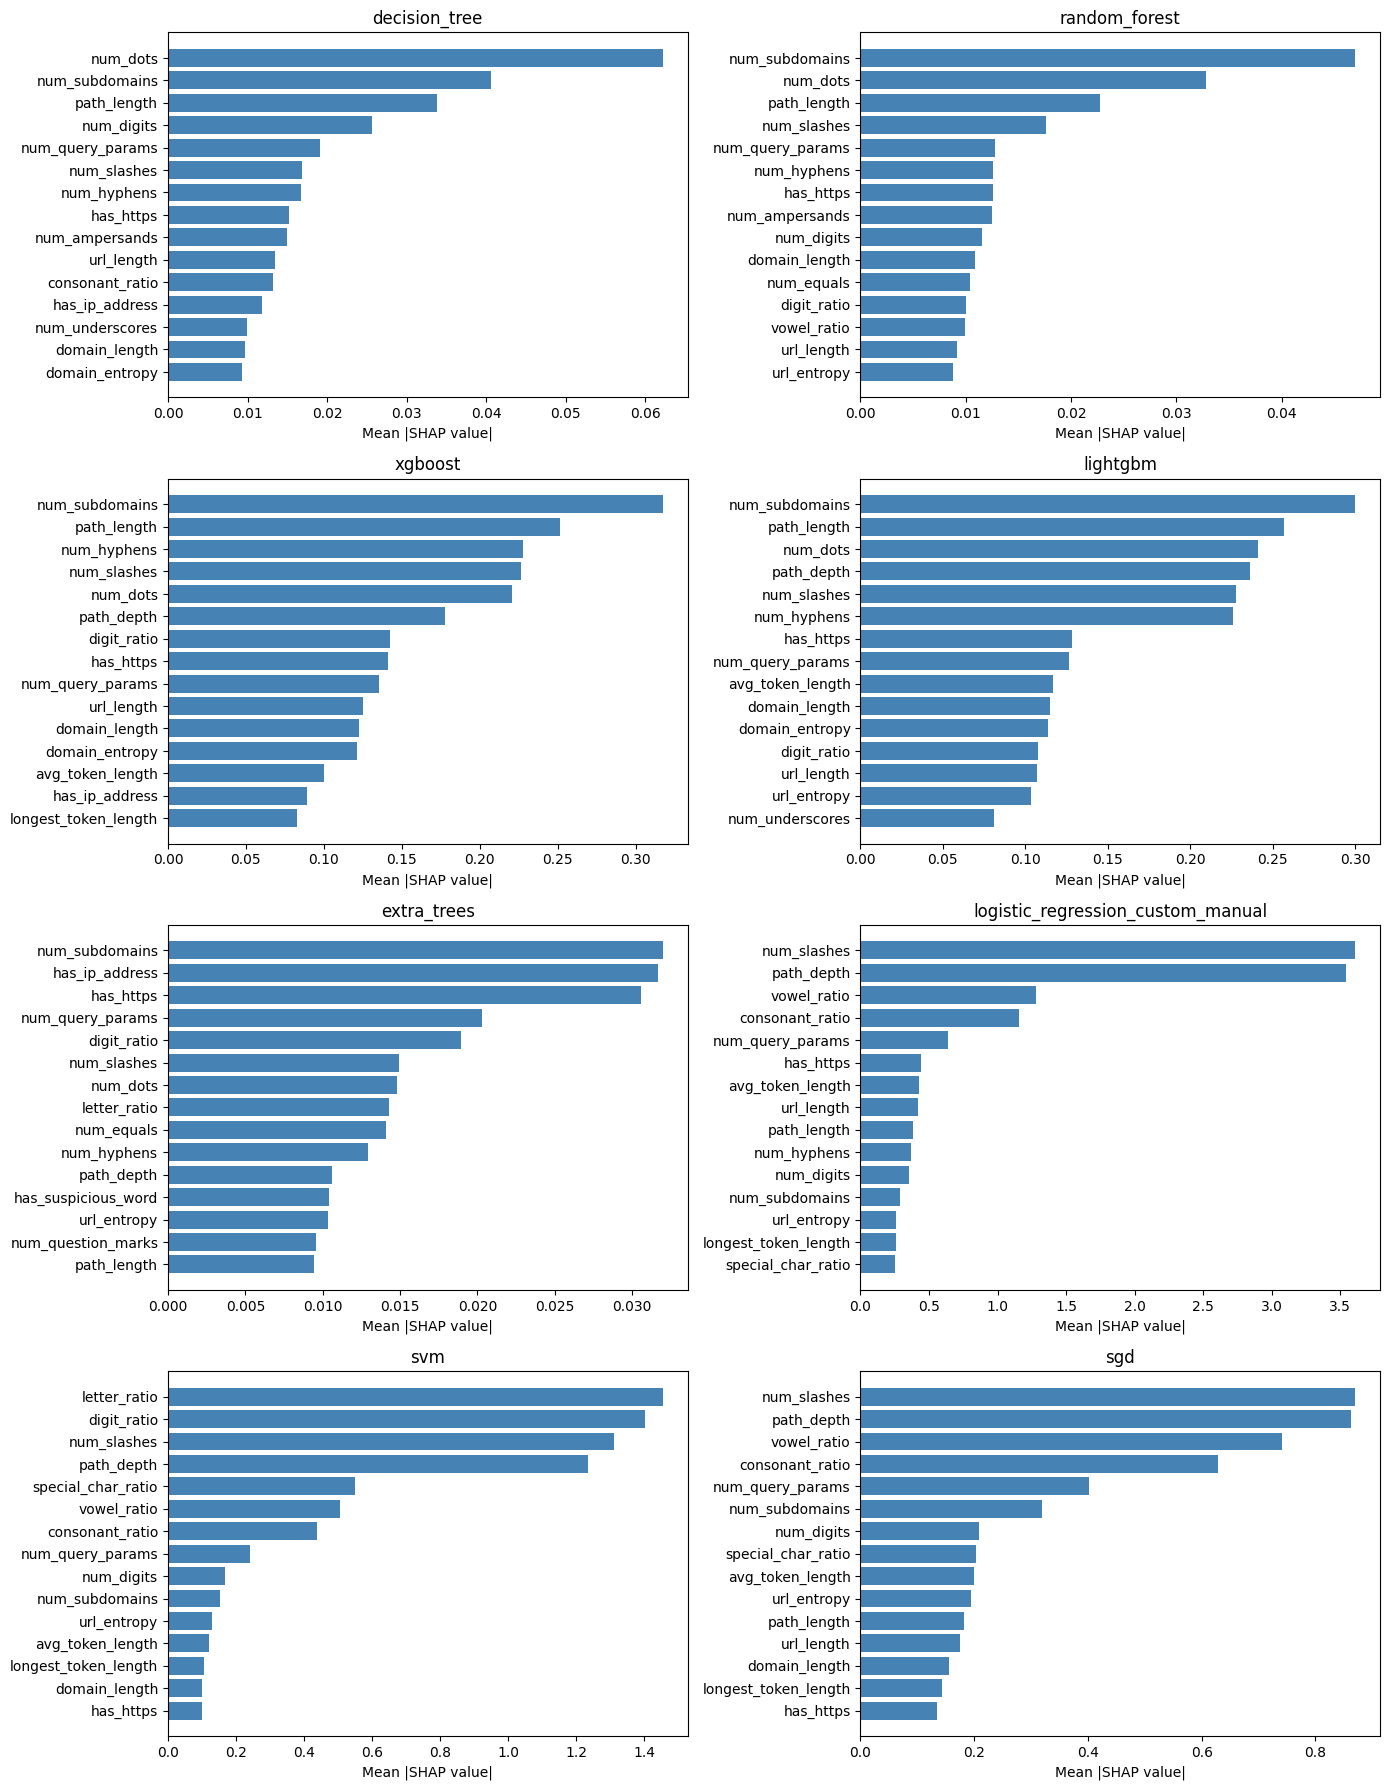

── Top 15 most important features by model ──
       decision_tree     random_forest               xgboost          lightgbm          extra_trees logistic_regression_custom_manual                   svm                   sgd
0           num_dots    num_subdomains        num_subdomains    num_subdomains       num_subdomains                       num_slashes          letter_ratio           num_slashes
1     num_subdomains          num_dots           path_length       path_length       has_ip_address                        path_depth           digit_ratio            path_depth
2        path_length       path_length           num_hyphens          num_dots            has_https                       vowel_ratio           num_slashes           vowel_ratio
3         num_digits       num_slashes           num_slashes        path_depth     num_query_params                   consonant_ratio            path_depth       consonant_ratio
4   num_query_params  num_query_params              num_dots    

In [6]:
# ── 4. Vẽ Global Feature Importance — Mean |SHAP| trung bình qua 4 lớp ──

def mean_abs_shap_per_feature(sv_list):
    stacked = np.stack([np.abs(sv).mean(axis=0) for sv in sv_list], axis=0)  # (n_class, n_feature)
    return stacked.mean(axis=0)  # (n_feature,)

importance_table = {}

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for ax, model_key in zip(axes, shap_values_global.keys()):
    sv_list = shap_values_global[model_key]['values']
    mean_abs = mean_abs_shap_per_feature(sv_list)
    importance_table[model_key] = mean_abs

    order = np.argsort(mean_abs)[::-1][:15]
    ax.barh([FEATURE_COLS[i] for i in order][::-1], mean_abs[order][::-1], color='steelblue')
    ax.set_title(model_key)
    ax.set_xlabel('Mean |SHAP value|')

plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'global_feature_importance_all_models.png'), dpi=150)
plt.show()

# ── Bảng so sánh top 15 feature giữa các model ──
importance_df = pd.DataFrame(importance_table, index=FEATURE_COLS)
top15_per_model = pd.DataFrame({
    mk: importance_df[mk].sort_values(ascending=False).head(15).index.tolist()
    for mk in importance_df.columns
})
print("── Top 15 most important features by model ──")
print(top15_per_model.to_string())

5. Local Explanation

5.1 Tree + Linear (8 model), all 7528 hard cases

In [7]:
# Local Explanation (Tier 2) — Tree + Linear models, all hard cases 

CHECKPOINT_PATH = os.path.join(BASE_DIR, 'Reports', 'shap_values_hard_cases.pkl')
shap_values_hard = {}

for model_key in TREE_MODELS + LINEAR_MODELS:
    model = models_ds1[model_key]
    X_full = get_input(model_key, X_hard, X_hard_scaled)

    t0 = time.time()
    if model_key in TREE_MODELS:
        explainer = shap.TreeExplainer(model)
        sv = explainer.shap_values(X_full, check_additivity=False)
    else:
        bg_source = get_input(model_key, X_val1, X_val1_scaled)
        bg_idx = rng.choice(len(bg_source), N_BACKGROUND, replace=False)
        explainer = shap.LinearExplainer(model, bg_source[bg_idx])
        sv = explainer.shap_values(X_full)

    sv_list = sv if isinstance(sv, list) else (
        [sv[:, :, c] for c in range(sv.shape[2])] if sv.ndim == 3 else [sv]
    )

    elapsed = round(time.time() - t0, 1)
    shap_values_hard[model_key] = sv_list
    print(f"[{elapsed:>7}s] {model_key:35s} → {len(sv_list)} class(es), shape {sv_list[0].shape}")

    # Checkpoint — lưu ngay sau mỗi model, tránh mất dữ liệu nếu bị ngắt giữa chừng
    joblib.dump(shap_values_hard, CHECKPOINT_PATH)

print(f"\nHoàn tất Local SHAP (Tree+Linear) cho {len(shap_values_hard)}/8 model, trên {len(X_hard)} hard cases")
print(f"Checkpoint: {CHECKPOINT_PATH}")

[   12.9s] decision_tree                       → 4 class(es), shape (7122, 32)
[ 7253.9s] random_forest                       → 4 class(es), shape (7122, 32)
[    5.1s] xgboost                             → 4 class(es), shape (7122, 32)
[    4.4s] lightgbm                            → 4 class(es), shape (7122, 32)


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


[ 3935.2s] extra_trees                         → 4 class(es), shape (7122, 32)


Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.
Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


[    0.2s] logistic_regression_custom_manual   → 4 class(es), shape (7122, 32)
[    0.0s] svm                                 → 4 class(es), shape (7122, 32)
[    0.0s] sgd                                 → 4 class(es), shape (7122, 32)

Hoàn tất Local SHAP (Tree+Linear) cho 8/8 model, trên 7122 hard cases
Checkpoint: d:\Study Assets\Final Project\PhishingGuard\Reports\shap_values_hard_cases.pkl


Test tốc độ trước khi chạy

In [8]:
# ── 6. Local Explanation (Tier 2) — Kernel-based: TEST tốc độ trước khi chạy full ──

N_TEST = 20
N_KMEANS_BACKGROUND = 50

for model_key in KERNEL_MODELS:
    model = models_ds1[model_key]
    X_full  = get_input(model_key, X_hard, X_hard_scaled)
    X_test  = X_full[:N_TEST]

    bg_source  = get_input(model_key, X_val1, X_val1_scaled)
    background = shap.kmeans(bg_source, N_KMEANS_BACKGROUND)

    predict_fn = model.predict_proba if hasattr(model, 'predict_proba') else model.decision_function
    explainer  = shap.KernelExplainer(predict_fn, background)

    t0 = time.time()
    sv_test = explainer.shap_values(X_test, nsamples=200)
    elapsed = time.time() - t0

    per_sample     = elapsed / N_TEST
    projected_full = per_sample * len(X_hard)

    print(f"{model_key:10s} — {N_TEST} sample: {elapsed:.1f}s, {per_sample:.2f}s/sample")
    print(f"  → Ước tính CHẠY FULL {len(X_hard)} hard cases: "
          f"{projected_full/60:.1f} phút (~{projected_full/3600:.2f} giờ)\n")

100%|██████████| 20/20 [00:28<00:00,  1.40s/it]


bagging    — 20 sample: 28.1s, 1.40s/sample
  → Ước tính CHẠY FULL 7122 hard cases: 166.8 phút (~2.78 giờ)



100%|██████████| 20/20 [01:12<00:00,  3.63s/it]

knn        — 20 sample: 72.5s, 3.63s/sample
  → Ước tính CHẠY FULL 7122 hard cases: 430.5 phút (~7.17 giờ)



Lấy mẫu stratified 2500 hard cases

In [9]:
from sklearn.model_selection import train_test_split

N_KERNEL_SAMPLE = 2500

kernel_idx, _ = train_test_split(
    np.arange(len(hard_cases)),
    train_size=N_KERNEL_SAMPLE,
    stratify=hard_cases['Label'],
    random_state=42
)

hard_cases_kernel   = hard_cases.iloc[kernel_idx].reset_index(drop=True)
X_hard_kernel        = X_hard[kernel_idx]
X_hard_kernel_scaled = X_hard_scaled[kernel_idx]

print(f"Stratified sample cho Kernel-based: {len(kernel_idx)}/{len(hard_cases)} hard cases")
print(hard_cases_kernel['Label'].value_counts())

Stratified sample cho Kernel-based: 2500/7122 hard cases
Label
defacement    911
phishing      888
benign        514
malware       187
Name: count, dtype: int64


Chạy full SHAP cho Bagging + kNN trên 2500 sample

In [10]:
N_KMEANS_BACKGROUND = 50
CHECKPOINT_KERNEL_PATH = os.path.join(BASE_DIR, 'Reports', 'shap_values_kernel_hard_cases.pkl')
shap_values_kernel = {}

for model_key in KERNEL_MODELS:   # ['bagging', 'knn'] — bagging chạy trước (nhanh hơn, quan trọng hơn)
    model = models_ds1[model_key]
    X_full = get_input(model_key, X_hard_kernel, X_hard_kernel_scaled)

    bg_source  = get_input(model_key, X_val1, X_val1_scaled)
    background = shap.kmeans(bg_source, N_KMEANS_BACKGROUND)

    predict_fn = model.predict_proba if hasattr(model, 'predict_proba') else model.decision_function
    explainer  = shap.KernelExplainer(predict_fn, background)

    print(f"\n── Đang chạy {model_key} trên {len(X_full)} sample ──")
    t0 = time.time()
    sv = explainer.shap_values(X_full, nsamples=200)
    elapsed = time.time() - t0

    sv_list = sv if isinstance(sv, list) else [sv]
    shap_values_kernel[model_key] = sv_list

    print(f"[{elapsed:.1f}s ({elapsed/60:.1f} phút)] {model_key} hoàn tất, shape {sv_list[0].shape}")

    joblib.dump(shap_values_kernel, CHECKPOINT_KERNEL_PATH)  # checkpoint ngay sau mỗi model
    print(f"  Checkpoint đã lưu")

print(f"\nHoàn tất Local SHAP (Kernel-based) cho {len(shap_values_kernel)}/{len(KERNEL_MODELS)} model")


── Đang chạy bagging trên 2500 sample ──


100%|██████████| 2500/2500 [53:15<00:00,  1.28s/it] 


[3195.6s (53.3 phút)] bagging hoàn tất, shape (2500, 32, 4)
  Checkpoint đã lưu

── Đang chạy knn trên 2500 sample ──


100%|██████████| 2500/2500 [12:46:23<00:00, 18.39s/it]     

[45983.2s (766.4 phút)] knn hoàn tất, shape (2500, 32, 4)
  Checkpoint đã lưu

Hoàn tất Local SHAP (Kernel-based) cho 2/2 model


In [11]:
# ── Chuẩn hóa lại shap_values_kernel về đúng định dạng list-per-class (giống các model khác) ──

for model_key in list(shap_values_kernel.keys()):
    sv = shap_values_kernel[model_key]
    current = sv[0] if isinstance(sv, list) and len(sv) == 1 else sv

    if hasattr(current, 'ndim') and current.ndim == 3:
        sv_list = [current[:, :, c] for c in range(current.shape[2])]
        shap_values_kernel[model_key] = sv_list
        print(f"{model_key}: đã chuẩn hóa → {len(sv_list)} class(es), shape {sv_list[0].shape}")
    else:
        print(f"{model_key}: đã đúng định dạng, giữ nguyên")

# Lưu đè lại checkpoint với định dạng đã chuẩn hóa
joblib.dump(shap_values_kernel, CHECKPOINT_KERNEL_PATH)
print("\nĐã cập nhật checkpoint")

bagging: đã chuẩn hóa → 4 class(es), shape (2500, 32)
knn: đã chuẩn hóa → 4 class(es), shape (2500, 32)

Đã cập nhật checkpoint


Dự đoán của 10 model trên hard cases:

In [12]:
# ── Predictions trên hard cases — biết model đoán SAI THÀNH LỚP NÀO ──
y_pred_hard = {}

for model_key in TREE_MODELS + LINEAR_MODELS:
    model = models_ds1[model_key]
    X_full = get_input(model_key, X_hard, X_hard_scaled)
    y_pred_hard[model_key] = model.predict(X_full)

for model_key in KERNEL_MODELS:
    model = models_ds1[model_key]
    X_full = get_input(model_key, X_hard_kernel, X_hard_kernel_scaled)
    y_pred_hard[model_key] = model.predict(X_full)

print("Done!")

Done!


So sánh Feature Importance: SHAP trên hard cases (lúc sai) vs SHAP Tier 1 (bình thường)

In [13]:
def mean_abs_shap(sv_list):
    return np.stack([np.abs(sv).mean(axis=0) for sv in sv_list], axis=0).mean(axis=0)

comparison_rows = []
for model_key in TREE_MODELS + LINEAR_MODELS:
    imp_normal = mean_abs_shap(shap_values_global[model_key]['values'])
    imp_hard   = mean_abs_shap(shap_values_hard[model_key])
    top_normal = FEATURE_COLS[np.argmax(imp_normal)]
    top_hard   = FEATURE_COLS[np.argmax(imp_hard)]
    comparison_rows.append({'model': model_key, 'top_feature_normal': top_normal, 'top_feature_hard_case': top_hard,
                             'changed': top_normal != top_hard})

for model_key in KERNEL_MODELS:
    imp_hard = mean_abs_shap(shap_values_kernel[model_key])
    top_hard = FEATURE_COLS[np.argmax(imp_hard)]
    comparison_rows.append({'model': model_key, 'top_feature_normal': '(chưa có Tier 1)', 'top_feature_hard_case': top_hard,
                             'changed': None})

comparison_df = pd.DataFrame(comparison_rows)
print("── Feature quan trọng nhất: bình thường vs khi model đoán sai ──")
print(comparison_df.to_string(index=False))

── Feature quan trọng nhất: bình thường vs khi model đoán sai ──
                            model top_feature_normal top_feature_hard_case changed
                    decision_tree           num_dots              num_dots   False
                    random_forest     num_subdomains        num_subdomains   False
                          xgboost     num_subdomains        num_subdomains   False
                         lightgbm     num_subdomains        num_subdomains   False
                      extra_trees     num_subdomains        num_subdomains   False
logistic_regression_custom_manual        num_slashes            path_depth    True
                              svm       letter_ratio           num_slashes    True
                              sgd        num_slashes           num_slashes   False
                          bagging   (chưa có Tier 1)        num_subdomains    None
                              knn   (chưa có Tier 1)        num_subdomains    None


Chọn ra case khó nhất + xem model đoán gì

In [14]:
worst_case_idx = hard_cases['n_models_wrong'].idxmax()
worst_case = hard_cases.loc[worst_case_idx]

print(f"URL: {worst_case['URL']}")
print(f"Nhãn thật: {worst_case['Label']}  |  {worst_case['n_models_wrong']}/{worst_case['n_models_total']} model đoán sai\n")

for model_key in ['random_forest', 'logistic_regression_custom_manual', 'bagging']:
    pred = y_pred_hard[model_key][hard_cases.index.get_loc(worst_case_idx)] if model_key in KERNEL_MODELS else y_pred_hard[model_key][worst_case_idx]
    print(f"{model_key:35s} → đoán: {LABEL_NAMES_1[pred]}")

URL: http://www.walldesk.net/default.asp?l=EN
Nhãn thật: phishing  |  16/16 model đoán sai

random_forest                       → đoán: defacement
logistic_regression_custom_manual   → đoán: defacement
bagging                             → đoán: benign


Waterfall plot cho case đó, 3 model đại diện (1 tree, 1 linear, 1 kernel):


── random_forest — giải thích vì sao đoán 'defacement' (thật: 'phishing') ──


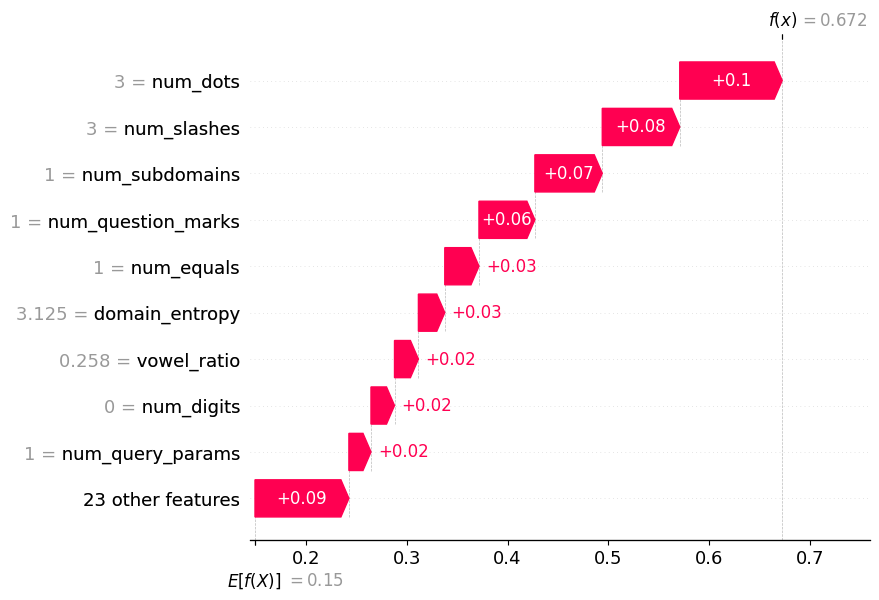

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.



── logistic_regression_custom_manual — giải thích vì sao đoán 'defacement' (thật: 'phishing') ──


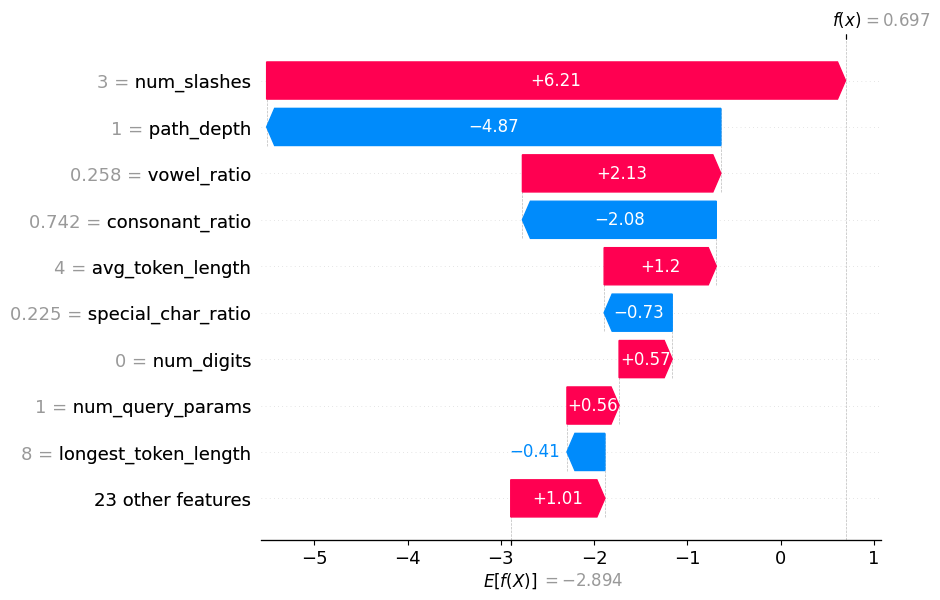


── bagging — giải thích vì sao đoán 'benign' (thật: 'phishing') ──


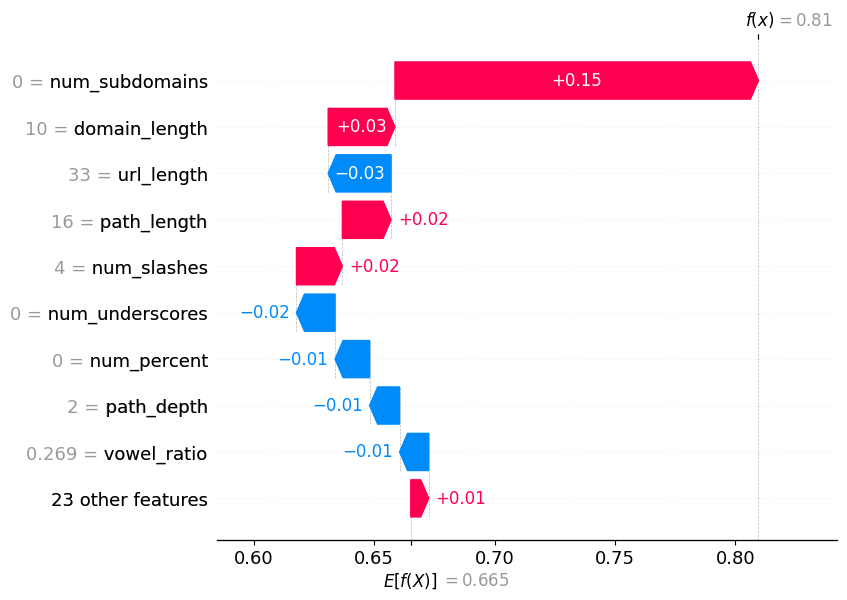

In [15]:
import shap as shap_lib

def get_expected_value(model_key):
    model = models_ds1[model_key]
    if model_key in TREE_MODELS:
        return shap.TreeExplainer(model).expected_value
    elif model_key in LINEAR_MODELS:
        bg = get_input(model_key, X_val1, X_val1_scaled)
        bg_idx = rng.choice(len(bg), N_BACKGROUND, replace=False)
        return shap.LinearExplainer(model, bg[bg_idx]).expected_value
    else:
        bg = shap.kmeans(get_input(model_key, X_val1, X_val1_scaled), N_KMEANS_BACKGROUND)
        predict_fn = model.predict_proba if hasattr(model, 'predict_proba') else model.decision_function
        return shap.KernelExplainer(predict_fn, bg).expected_value

true_class = label_to_idx[worst_case['Label']]

for model_key in ['random_forest', 'logistic_regression_custom_manual', 'bagging']:
    row_idx = worst_case_idx if model_key not in KERNEL_MODELS else hard_cases.index.get_loc(worst_case_idx)
    sv_dict = shap_values_hard if model_key not in KERNEL_MODELS else shap_values_kernel
    X_data  = X_hard if model_key not in KERNEL_MODELS else X_hard_kernel

    pred_class = y_pred_hard[model_key][row_idx]
    expected_val = get_expected_value(model_key)
    ev = expected_val[pred_class] if hasattr(expected_val, '__len__') else expected_val

    explanation = shap.Explanation(
        values=sv_dict[model_key][pred_class][row_idx],
        base_values=ev,
        data=X_data[row_idx],
        feature_names=FEATURE_COLS
    )
    print(f"\n── {model_key} — giải thích vì sao đoán '{LABEL_NAMES_1[pred_class]}' (thật: '{worst_case['Label']}') ──")
    shap.plots.waterfall(explanation, show=False)
    plt.savefig(os.path.join(IMAGES_DIR, f'waterfall_{model_key}_worst_case.png'), dpi=150, bbox_inches='tight')
    plt.show()

7. Feature Selection dựa trên SHAP Global Importance (Tier 1)

── Xếp hạng feature đồng thuận từ 8 model (SHAP Tier 1) ──
                      mean_rank  mean_norm_shap  n_models_top10  rank_std
num_slashes                3.75          0.1015               8      1.98
num_subdomains             4.25          0.0798               7      4.53
num_query_params           6.12          0.0462               8      1.89
path_length                7.62          0.0522               5      5.90
path_depth                 7.62          0.0898               5      5.90
has_https                  8.62          0.0399               6      4.24
num_dots                   9.50          0.0620               5      8.38
num_hyphens                9.75          0.0395               6      5.68
digit_ratio               11.62          0.0462               3      6.52
num_digits                12.25          0.0307               4      6.32
vowel_ratio               12.25          0.0473               3      7.19
url_length                12.62          0.0288      

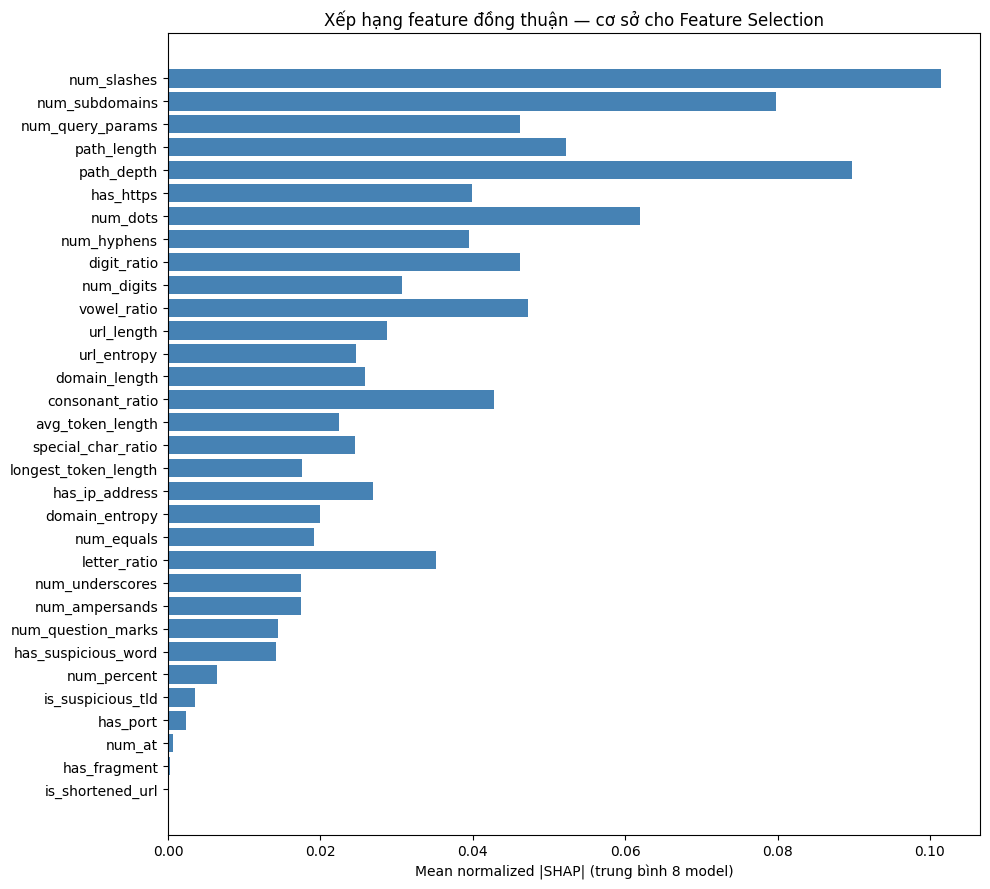

In [16]:
def mean_abs_shap(sv_list):
    return np.stack([np.abs(sv).mean(axis=0) for sv in sv_list], axis=0).mean(axis=0)

rank_table, norm_table = {}, {}
for model_key, info in shap_values_global.items():
    imp = mean_abs_shap(info['values'])
    norm_table[model_key] = imp / imp.sum()                                   # tỉ lệ đóng góp (chuẩn hoá thang đo)
    rank_table[model_key] = pd.Series(imp, index=FEATURE_COLS).rank(ascending=False)

rank_df = pd.DataFrame(rank_table, index=FEATURE_COLS)
norm_df = pd.DataFrame(norm_table, index=FEATURE_COLS)

consensus = pd.DataFrame({
    'mean_rank':      rank_df.mean(axis=1).round(2),
    'mean_norm_shap': norm_df.mean(axis=1).round(4),
    'n_models_top10': (rank_df <= 10).sum(axis=1),
    'rank_std':       rank_df.std(axis=1).round(2),      # độ bất đồng giữa các model
}).sort_values('mean_rank')

FEATURE_RANKING = consensus.index.tolist()

print(f"── Xếp hạng feature đồng thuận từ {len(shap_values_global)} model (SHAP Tier 1) ──")
print(consensus.to_string())

plt.figure(figsize=(10, 9))
plt.barh(consensus.index[::-1], consensus['mean_norm_shap'][::-1], color='steelblue')
plt.xlabel('Mean normalized |SHAP| (trung bình 8 model)')
plt.title('Xếp hạng feature đồng thuận — cơ sở cho Feature Selection')
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'feature_ranking_consensus.png'), dpi=150)
plt.show()

Train lại với nhiều mức k feature, đo accuracy + macro-F1

In [17]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Train set — explainability.ipynb trước giờ chỉ load val, giờ cần thêm train
train1 = pd.read_csv(os.path.join(TRAIN_TEST_DIR, 'dataset1', 'train.csv'))
X_train_all = train1[FEATURE_COLS].values
y_train_all = train1['Label'].map(label_to_idx).values
print(f"Train set: {X_train_all.shape} | Val set: {X_val1.shape}")

K_LIST = [5, 8, 10, 12, 15, 20, 25, 32]

# Chỉ dùng model tree-based NHANH — tránh random_forest/extra_trees max_depth=20 vốn đã chậm
CANDIDATES = {
    'lightgbm':      lambda: LGBMClassifier(objective='multiclass', num_class=4, n_estimators=100,
                                             random_state=42, n_jobs=-1, verbose=-1),
    'xgboost':       lambda: XGBClassifier(n_estimators=100, max_depth=6, random_state=42,
                                            n_jobs=-1, eval_metric='mlogloss'),
    'decision_tree': lambda: DecisionTreeClassifier(max_depth=15, random_state=42),
}

fs_results = []
for k in K_LIST:
    cols = FEATURE_RANKING[:k]
    idx  = [FEATURE_COLS.index(c) for c in cols]
    Xtr, Xva = X_train_all[:, idx], X_val1[:, idx]

    for name, make_model in CANDIDATES.items():
        t0 = time.time()
        m = make_model()
        m.fit(Xtr, y_train_all)
        y_pred = m.predict(Xva)
        fs_results.append({
            'k': k, 'model': name,
            'accuracy': round(accuracy_score(y_val1, y_pred), 4),
            'macro_f1': round(f1_score(y_val1, y_pred, average='macro'), 4),
            'train_time': round(time.time() - t0, 1),
        })
        print(f"k={k:2d} | {name:14s} acc={fs_results[-1]['accuracy']:.4f} "
              f"macroF1={fs_results[-1]['macro_f1']:.4f} ({fs_results[-1]['train_time']}s)")

fs_df = pd.DataFrame(fs_results)
fs_df.to_csv(os.path.join(MODELS_DIR, 'feature_selection_results.csv'), index=False)

Train set: (407794, 32) | Val set: (101949, 32)
k= 5 | lightgbm       acc=0.8157 macroF1=0.6988 (1.6s)
k= 5 | xgboost        acc=0.8182 macroF1=0.7031 (2.2s)
k= 5 | decision_tree  acc=0.8175 macroF1=0.7019 (0.4s)
k= 8 | lightgbm       acc=0.8466 macroF1=0.7822 (1.8s)
k= 8 | xgboost        acc=0.8489 macroF1=0.7857 (2.3s)
k= 8 | decision_tree  acc=0.8508 macroF1=0.7906 (0.6s)
k=10 | lightgbm       acc=0.8671 macroF1=0.8240 (1.6s)
k=10 | xgboost        acc=0.8733 macroF1=0.8327 (2.1s)
k=10 | decision_tree  acc=0.8690 macroF1=0.8249 (0.9s)
k=12 | lightgbm       acc=0.8765 macroF1=0.8343 (1.9s)
k=12 | xgboost        acc=0.8834 macroF1=0.8446 (2.2s)
k=12 | decision_tree  acc=0.8721 macroF1=0.8254 (1.4s)
k=15 | lightgbm       acc=0.8831 macroF1=0.8441 (1.9s)
k=15 | xgboost        acc=0.8912 macroF1=0.8558 (2.5s)
k=15 | decision_tree  acc=0.8771 macroF1=0.8333 (2.9s)
k=20 | lightgbm       acc=0.8955 macroF1=0.8591 (2.5s)
k=20 | xgboost        acc=0.9075 macroF1=0.8763 (2.7s)
k=20 | decision_t

Vẽ biểu đồ so sánh + xác định k tối ưu:

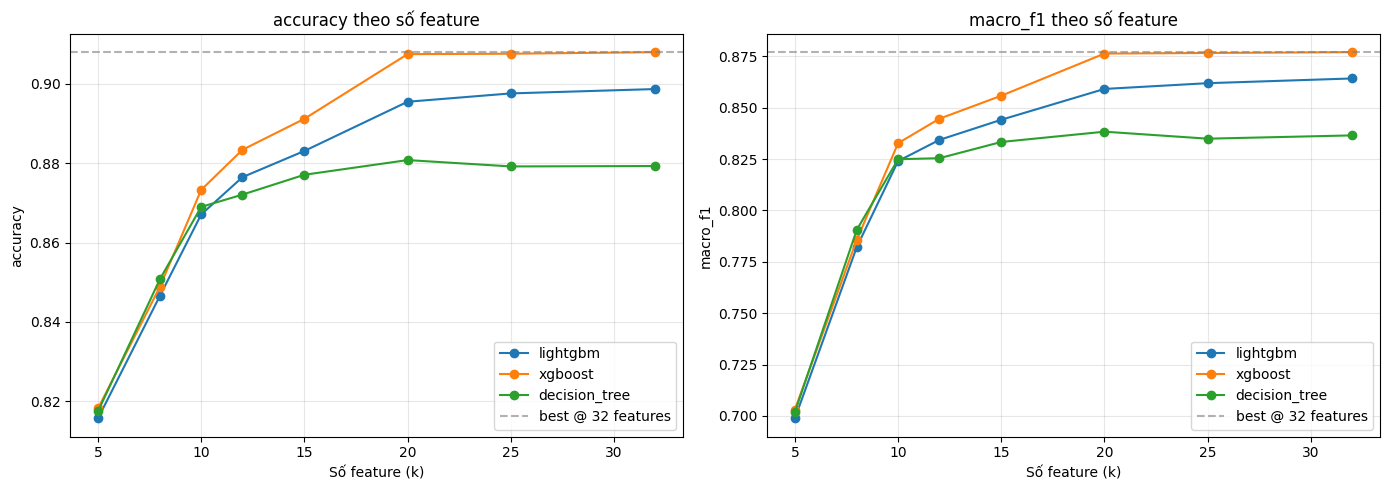

── So sánh: k tối ưu vs full 32 feature ──
lightgbm       | best k=32: acc=0.8987 f1=0.8642  vs  32 feature: acc=0.8987 f1=0.8642  → Δf1=+0.0000
xgboost        | best k=32: acc=0.9080 f1=0.8770  vs  32 feature: acc=0.9080 f1=0.8770  → Δf1=+0.0000
decision_tree  | best k=20: acc=0.8808 f1=0.8383  vs  32 feature: acc=0.8793 f1=0.8365  → Δf1=+0.0018


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for metric, ax in zip(['accuracy', 'macro_f1'], axes):
    for name in CANDIDATES:
        sub = fs_df[fs_df['model'] == name].sort_values('k')
        ax.plot(sub['k'], sub[metric], marker='o', label=name)
    baseline = fs_df[(fs_df['k'] == 32)].set_index('model')[metric]
    ax.axhline(baseline.max(), ls='--', c='gray', alpha=0.6, label='best @ 32 features')
    ax.set_xlabel('Số feature (k)'); ax.set_ylabel(metric); ax.set_title(f'{metric} theo số feature')
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'feature_selection_curve.png'), dpi=150)
plt.show()

# So sánh mỗi model: k tốt nhất vs dùng đủ 32 feature
print("── So sánh: k tối ưu vs full 32 feature ──")
for name in CANDIDATES:
    sub  = fs_df[fs_df['model'] == name]
    best = sub.loc[sub['macro_f1'].idxmax()]
    full = sub[sub['k'] == 32].iloc[0]
    print(f"{name:14s} | best k={int(best['k']):2d}: acc={best['accuracy']:.4f} f1={best['macro_f1']:.4f}"
          f"  vs  32 feature: acc={full['accuracy']:.4f} f1={full['macro_f1']:.4f}"
          f"  → Δf1={best['macro_f1']-full['macro_f1']:+.4f}")

In [19]:
TOLERANCE = 0.99   # chấp nhận mất tối đa 1% macro-F1 so với dùng đủ 32 feature

print("── k tối ưu: nhỏ nhất mà vẫn giữ ≥99% macro-F1 của bản 32 feature ──")
for name in CANDIDATES:
    sub = fs_df[fs_df['model'] == name].sort_values('k')
    full_f1 = sub[sub['k'] == 32]['macro_f1'].iloc[0]
    ok = sub[sub['macro_f1'] >= full_f1 * TOLERANCE]
    best_k = int(ok['k'].min())
    row = sub[sub['k'] == best_k].iloc[0]
    print(f"{name:14s} | k={best_k:2d} (giảm {(32-best_k)/32*100:.0f}% feature) "
          f"acc={row['accuracy']:.4f} f1={row['macro_f1']:.4f} "
          f"| giữ được {row['macro_f1']/full_f1*100:.1f}% chất lượng")

SELECTED_FEATURES = FEATURE_RANKING[:20]
print(f"\n── 20 feature được chọn ──\n{SELECTED_FEATURES}")

removed = [f for f in FEATURE_COLS if f not in SELECTED_FEATURES]
print(f"\n── 12 feature bị loại ──\n{removed}")

── k tối ưu: nhỏ nhất mà vẫn giữ ≥99% macro-F1 của bản 32 feature ──
lightgbm       | k=20 (giảm 38% feature) acc=0.8955 f1=0.8591 | giữ được 99.4% chất lượng
xgboost        | k=20 (giảm 38% feature) acc=0.9075 f1=0.8763 | giữ được 99.9% chất lượng
decision_tree  | k=15 (giảm 53% feature) acc=0.8771 f1=0.8333 | giữ được 99.6% chất lượng

── 20 feature được chọn ──
['num_slashes', 'num_subdomains', 'num_query_params', 'path_length', 'path_depth', 'has_https', 'num_dots', 'num_hyphens', 'digit_ratio', 'num_digits', 'vowel_ratio', 'url_length', 'url_entropy', 'domain_length', 'consonant_ratio', 'avg_token_length', 'special_char_ratio', 'longest_token_length', 'has_ip_address', 'domain_entropy']

── 12 feature bị loại ──
['num_underscores', 'num_at', 'num_question_marks', 'num_equals', 'num_ampersands', 'num_percent', 'letter_ratio', 'is_suspicious_tld', 'has_port', 'has_fragment', 'is_shortened_url', 'has_suspicious_word']


Cấu hình + lấy hyperparameter từ model gốc

In [20]:
import json
from sklearn.base import clone
from sklearn.metrics import f1_score, accuracy_score, recall_score, classification_report
 
BENIGN_IDX = label_to_idx['benign']
CLASSES    = list(range(len(LABEL_NAMES_1)))
 
K_LIST       = [5, 8, 10, 12, 15, 20, 25, 32]
TOLERANCE    = 0.99    # giữ >= 99% macro-F1 của bản 32 feature
RECALL_TOL   = 0.02    # không lớp nào được tụt recall quá 2 điểm % so với bản 32 feature
N_BOOT       = 100     # số lần bootstrap trên val để ước lượng độ nhiễu
SELECT_MODELS = ['lightgbm', 'xgboost', 'decision_tree']
 
# Clone từ chính model đã train trong modeling.ipynb => hyperparameter KHỚP bản gốc
base_models = {k: joblib.load(os.path.join(MODELS_DIR, 'dataset1', f'{k}.pkl')) for k in SELECT_MODELS}
for k, m in base_models.items():
    print(k, m.get_params(), '\n')

lightgbm {'boosting_type': 'gbdt', 'class_weight': None, 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.1, 'max_depth': -1, 'min_child_samples': 20, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 100, 'n_jobs': -1, 'num_leaves': 31, 'objective': 'multiclass', 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1.0, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'num_class': 4, 'verbose': -1} 

xgboost {'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'mlogloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'm

train lại theo từng k, lưu dự đoán trên VAL

In [21]:
val_pred = {}
for name, base in base_models.items():
    for k in K_LIST:
        idx = [FEATURE_COLS.index(c) for c in FEATURE_RANKING[:k]]
        m = clone(base)
        m.fit(X_train_all[:, idx], y_train_all)
        val_pred[(name, k)] = m.predict(X_val1[:, idx])
        print(f"xong {name:14s} k={k:2d}")

xong lightgbm       k= 5
xong lightgbm       k= 8
xong lightgbm       k=10
xong lightgbm       k=12
xong lightgbm       k=15
xong lightgbm       k=20
xong lightgbm       k=25
xong lightgbm       k=32
xong xgboost        k= 5
xong xgboost        k= 8
xong xgboost        k=10
xong xgboost        k=12
xong xgboost        k=15
xong xgboost        k=20
xong xgboost        k=25
xong xgboost        k=32
xong decision_tree  k= 5
xong decision_tree  k= 8
xong decision_tree  k=10
xong decision_tree  k=12
xong decision_tree  k=15
xong decision_tree  k=20
xong decision_tree  k=25
xong decision_tree  k=32


tính metric (macro-F1, accuracy, recall từng lớp, FPR benign)

In [22]:
def metrics(y_true, y_pred):
    rec = recall_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0)
    d = {
        'acc': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
        'benign_fpr': float(np.mean(y_pred[y_true == BENIGN_IDX] != BENIGN_IDX)),  # benign bị chặn nhầm
    }
    d.update({f'recall_{LABEL_NAMES_1[c]}': rec[c] for c in CLASSES})
    return d
 
res = pd.DataFrame([{'model': n, 'k': k, **metrics(y_val1, yp)} for (n, k), yp in val_pred.items()])
res.to_csv(os.path.join(MODELS_DIR, 'feature_selection_results_v2.csv'), index=False)
 
full = res[res.k == max(K_LIST)].set_index('model')
res['f1_ratio'] = res.apply(lambda r: r.macro_f1 / full.loc[r.model, 'macro_f1'], axis=1)
 
print("Tỉ lệ macro-F1 so với k=32:")
display(res.pivot(index='k', columns='model', values='f1_ratio').round(4))
print("Recall từng lớp (LightGBM):")
display(res[res.model == 'lightgbm'].set_index('k')[[c for c in res.columns if c.startswith('recall_')]].round(4))

Tỉ lệ macro-F1 so với k=32:


model,decision_tree,lightgbm,xgboost
k,,,
5,0.8390,0.8086,0.8095
8,0.9451,0.9051,0.9007
10,0.9861,0.9535,0.9548
12,0.9867,0.9654,0.9687
15,0.9962,0.9768,0.9797
20,1.0021,0.9941,0.9979
25,0.9981,0.9974,0.9999
32,1.0000,1.0000,1.0000


Recall từng lớp (LightGBM):


,recall_benign,recall_defacement,recall_malware,recall_phishing
k,,,,
5,0.9563,0.5492,0.5424,0.5202
8,0.9386,0.6613,0.7832,0.6355
10,0.9455,0.7207,0.8210,0.6739
12,0.9533,0.7320,0.8311,0.6881
15,0.9559,0.7524,0.8438,0.6976
20,0.9624,0.7790,0.8543,0.7224
25,0.9634,0.7869,0.8546,0.7236
32,0.9637,0.7870,0.8604,0.7288


bootstrap — chênh lệch macro-F1 (k so với 32) có vượt độ nhiễu không?

In [23]:
rng_b = np.random.RandomState(0)
boot_idx = rng_b.randint(0, len(y_val1), size=(N_BOOT, len(y_val1))).astype(np.int32)
 
ci_rows = []
for name in SELECT_MODELS:
    ref = val_pred[(name, max(K_LIST))]
    for k in K_LIST[:-1]:
        a = val_pred[(name, k)]
        d = [f1_score(y_val1[b], a[b], average='macro') - f1_score(y_val1[b], ref[b], average='macro')
             for b in boot_idx]
        lo, hi = np.percentile(d, [2.5, 97.5])
        ci_rows.append({'model': name, 'k': k, 'delta_f1_mean': np.mean(d), 'ci_low': lo, 'ci_high': hi})
ci_df = pd.DataFrame(ci_rows)
print("Δ macro-F1 (k so với 32) với khoảng tin cậy 95%:")
display(ci_df.round(4))

Δ macro-F1 (k so với 32) với khoảng tin cậy 95%:


,model,k,delta_f1_mean,ci_low,ci_high
0,lightgbm,5,-0.1652,-0.1695,-0.1612
1,lightgbm,8,-0.0820,-0.0845,-0.0786
2,lightgbm,10,-0.0400,-0.0419,-0.0379
3,lightgbm,12,-0.0298,-0.0315,-0.0280
4,lightgbm,15,-0.0200,-0.0217,-0.0183
5,lightgbm,20,-0.0051,-0.0067,-0.0039
6,lightgbm,25,-0.0022,-0.0034,-0.0010
7,xgboost,5,-0.1647,-0.1686,-0.1609
8,xgboost,8,-0.0860,-0.0884,-0.0825
9,xgboost,10,-0.0391,-0.0412,-0.0370


chọn k theo tiêu chí chung cho cả 3 model

In [24]:
recall_cols = [c for c in res.columns if c.startswith('recall_')]
 
def passes(row):
    f = full.loc[row.model]
    f1_ok  = row.macro_f1 >= f.macro_f1 * TOLERANCE
    rec_ok = all((f[c] - row[c]) <= RECALL_TOL for c in recall_cols)
    return f1_ok and rec_ok
 
res['pass'] = res.apply(passes, axis=1)
pass_by_k = res.groupby('k')['pass'].all()
print("k nào thỏa trên CẢ 3 model:")
print(pass_by_k.to_string())
 
k_opt = int(pass_by_k[pass_by_k].index.min()) if pass_by_k.any() else max(K_LIST)
SELECTED_FEATURES = FEATURE_RANKING[:k_opt]
removed = [f for f in FEATURE_COLS if f not in SELECTED_FEATURES]
print(f"\nk tối ưu = {k_opt} (giảm {(32 - k_opt) / 32 * 100:.0f}% feature)")
print("Giữ lại:", SELECTED_FEATURES)
print("Loại bỏ:", removed)

k nào thỏa trên CẢ 3 model:
k
5     False
8     False
10    False
12    False
15    False
20     True
25     True
32     True

k tối ưu = 20 (giảm 38% feature)
Giữ lại: ['num_slashes', 'num_subdomains', 'num_query_params', 'path_length', 'path_depth', 'has_https', 'num_dots', 'num_hyphens', 'digit_ratio', 'num_digits', 'vowel_ratio', 'url_length', 'url_entropy', 'domain_length', 'consonant_ratio', 'avg_token_length', 'special_char_ratio', 'longest_token_length', 'has_ip_address', 'domain_entropy']
Loại bỏ: ['num_underscores', 'num_at', 'num_question_marks', 'num_equals', 'num_ampersands', 'num_percent', 'letter_ratio', 'is_suspicious_tld', 'has_port', 'has_fragment', 'is_shortened_url', 'has_suspicious_word']


đồ thị + lưu danh sách feature cuối (FastAPI sẽ dùng lại file JSON này)

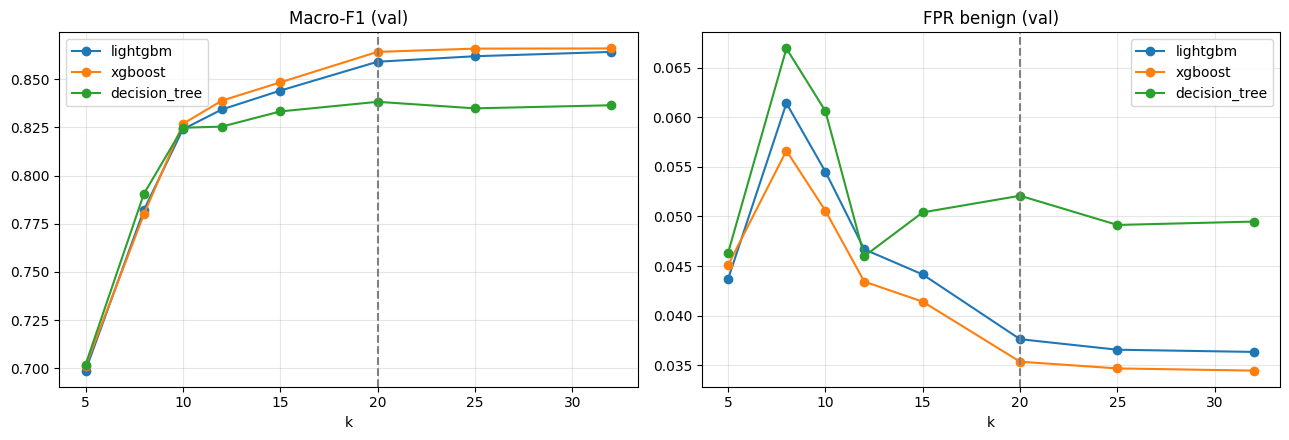

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name in SELECT_MODELS:
    sub = res[res.model == name].sort_values('k')
    axes[0].plot(sub.k, sub.macro_f1, marker='o', label=name)
    axes[1].plot(sub.k, sub.benign_fpr, marker='o', label=name)
for ax, t in zip(axes, ['Macro-F1 (val)', 'FPR benign (val)']):
    ax.axvline(k_opt, ls='--', c='gray'); ax.set_title(t); ax.set_xlabel('k'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig(os.path.join(IMAGES_DIR, 'feature_selection_curve_v2.png'), dpi=150)
plt.show()
 
with open(os.path.join(MODELS_DIR, 'final_features.json'), 'w', encoding='utf-8') as f:
    json.dump({'k': k_opt, 'features': SELECTED_FEATURES, 'dropped': removed}, f, indent=2, ensure_ascii=False)

ĐÁNH GIÁ CUỐI trên TEST (chỉ chạy SAU KHI đã chốt k_opt, không dùng test để chọn k)

In [28]:
test_path = os.path.join(TRAIN_TEST_DIR, 'dataset1', 'test.csv')   # sửa tên file nếu khác
if not os.path.exists(test_path):
    print("Không thấy test.csv, kiểm tra lại đường dẫn:", test_path)
else:
    test1  = pd.read_csv(test_path)
    X_test = test1[FEATURE_COLS].values
    y_test = test1['Label'].map(label_to_idx).values
 
    for tag, feats in [('32 feature', FEATURE_COLS), (f'{k_opt} feature', SELECTED_FEATURES)]:
        idx = [FEATURE_COLS.index(c) for c in feats]
        m = clone(base_models['lightgbm'])
        m.fit(X_train_all[:, idx], y_train_all)
        yp = m.predict(X_test[:, idx])
        fpr = np.mean(yp[y_test == BENIGN_IDX] != BENIGN_IDX)
        print(f"\n===== LightGBM, {tag} | TEST | benign FPR = {fpr:.4f} =====")
        print(classification_report(y_test, yp, target_names=LABEL_NAMES_1, digits=4))
        if tag != '32 feature':
            joblib.dump(m, os.path.join(MODELS_DIR, 'dataset1', 'lightgbm_final.pkl'))
            print("Đã lưu lightgbm_final.pkl (model triển khai). LightGBM dùng feature thô, không cần scaler.")

Không thấy test.csv, kiểm tra lại đường dẫn: d:\Study Assets\Final Project\PhishingGuard\Models\Train_Test\dataset1\test.csv
